# 02 — Target e features
1. Consolidar as parcelas e construir o **target** (inadimplente = alguma das 6 primeiras parcelas com DPD > 5 dias; alternativo: > 30 dias).
2. Comparar os dois targets e medir o **balanceamento** das classes.
3. Separar os dados **fora do tempo** (treino / validação / teste).
4. Montar a base de modelagem (só o que se conhece na solicitação) e fazer a **análise bivariada e a seleção, usando só o treino**.

Regras: `docs/PLANO.md` e `docs/DECISOES.md` (itens 1.5 a 1.10). Lógica em `src/features.py` e `src/evaluate.py`.

In [1]:
import sys; sys.path.insert(0, '../src')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor
import data_loader as dl, features as ft
from config import DATA_OBSERVACAO, GERADOS, OUTPUTS, DATA_CORTE_TREINO, DATA_CORTE_VALID
from evaluate import psi, iv_woe

pd.set_option('display.width', 200, 'display.max_columns', 60, 'display.max_rows', 100)
sns.set_theme(style='whitegrid')
OBS = pd.Timestamp(DATA_OBSERVACAO); FIG, TAB = OUTPUTS / 'figures', OUTPUTS / 'tables'; GERADOS.mkdir(exist_ok=True)

cad, sub, emp, par = dl.carregar_cadastral(), dl.carregar_submissao(), dl.carregar_emprestimos(), dl.carregar_parcelas()

## 1. Consolidação das parcelas e target

In [2]:
pc = ft.consolidar_parcelas(par)
print(f'{len(par):,} linhas de pagamento -> {len(pc):,} parcelas | quitadas: {pc.quitada.mean():.2%}')
tg = ft.construir_target(pc, OBS)
print(f'{len(tg):,} contratos com parcelas; DPD máximo na janela de {ft.N_PARCELAS_JANELA if hasattr(ft, "N_PARCELAS_JANELA") else 6} parcelas:')
display(tg.dpd_max.describe().round(1).to_frame('dpd_max').T)
print('contratos com DPD máx. <= 0 (nunca atrasaram):', f'{(tg.dpd_max <= 0).mean():.1%}', '| com DPD máx. entre 1 e 5:', f'{tg.dpd_max.between(1, 5).mean():.1%}')

1,659,408 linhas de pagamento -> 1,574,411 parcelas | quitadas: 99.75%


122,867 contratos com parcelas; DPD máximo na janela de 6 parcelas:


,count,mean,std,min,25%,50%,75%,max
dpd_max,122867.0,15.9,154.0,-917.0,-8.0,-1.0,3.0,2893.0


contratos com DPD máx. <= 0 (nunca atrasaram): 67.7% | com DPD máx. entre 1 e 5: 12.5%


### 1.1 Funil: de aprovados a contratos com target

In [3]:
a = emp[emp.status_contrato == 'Aprovado'].merge(tg, on='id_contrato', how='left')
def motivo(r):
    if pd.isna(r.n_parcelas_janela): return '1. sem parcelas (1ª parcela ainda não venceu)'
    if r.n_parcelas_janela < 6: return '2. menos de 6 parcelas planejadas' if r.qtd_parcelas_planejadas < 6 else '3. planejadas >= 6, mas < 6 vencidas'
    if pd.isna(r.target_dpd5): return '4. 6ª parcela venceu há <= 5 dias (imaturo)'
    return '5. com target (DPD > 5)'
a['situacao'] = a.apply(motivo, axis=1)
f = a.situacao.value_counts().sort_index().to_frame('contratos'); f['%'] = (f.contratos / f.contratos.sum() * 100).round(1); display(f)
print('com target DPD > 30:', int(a.target_dpd30.notna().sum()), '| com target DPD > 5:', int(a.target_dpd5.notna().sum()))
print('tipo_contrato — com target:', a[a.target_dpd5.notna()].tipo_contrato.value_counts(normalize=True).round(3).to_dict())
print('tipo_contrato — todos os aprovados:', a.tipo_contrato.value_counts(normalize=True).round(3).to_dict())

,contratos,%
situacao,,
1. sem parcelas (1ª parcela ainda não venceu),8868,6.7
2. menos de 6 parcelas planejadas,3528,2.7
"3. planejadas >= 6, mas < 6 vencidas",20450,15.5
4. 6ª parcela venceu há <= 5 dias (imaturo),32,0.0
5. com target (DPD > 5),98857,75.0


com target DPD > 30: 98113 | com target DPD > 5: 98861
tipo_contrato — com target: {'Empréstimo em dinheiro': 0.378, 'Financiamento de consumo': 0.369, 'Crédito rotativo': 0.252}
tipo_contrato — todos os aprovados: {'Empréstimo em dinheiro': 0.38, 'Financiamento de consumo': 0.369, 'Crédito rotativo': 0.252}


Os contratos sem a janela completa saem do target pela regra de maturidade do plano. Os grupos 2 e 3 (≈ 24 mil) são ambíguos: parcelas ausentes podem ser quitação antecipada ou inadimplência. A mistura de `tipo_contrato` praticamente não muda, mas **o viés de seleção por esse critério fica registrado como limitação**.

### 1.2 Comparação dos dois targets

,DPD > 5,DPD > 30
contratos maduros,98861.0000,98113.0000
taxa de inadimplência,0.2246,0.0944
inadimplentes,22203.0000,9266.0000


todo DPD > 30 também é DPD > 5? True


DPD>30,0.0,1.0,All
DPD>5,,,
0.0,76057,0,76057
1.0,12790,9266,22056
All,88847,9266,98113


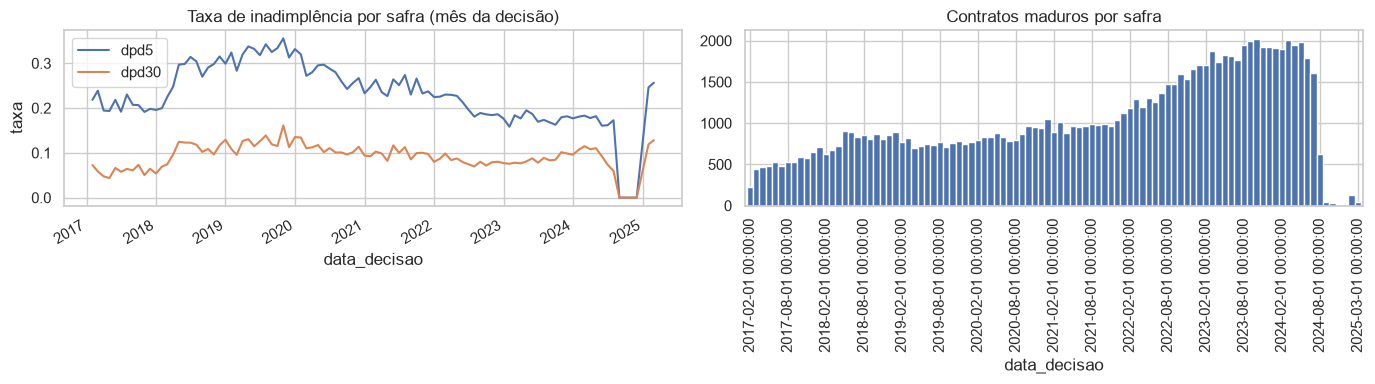

ano,2017,2018,2019,2020,2021,2022,2023,2024,2025
n,5488.000,9545.000,9158.000,10247.000,11679.000,16463.000,22255.000,13861.000,165.000
dpd5,0.207,0.275,0.323,0.281,0.247,0.204,0.176,0.174,0.248
dpd30,0.060,0.103,0.123,0.111,0.098,0.080,0.084,0.101,0.121


In [4]:
m = a[a.target_dpd5.notna()].copy(); m['ano'] = m.data_decisao.dt.year
comp = pd.DataFrame({
    'DPD > 5': [m.target_dpd5.notna().sum(), m.target_dpd5.mean(), m.target_dpd5.sum()],
    'DPD > 30': [m.target_dpd30.notna().sum(), m.target_dpd30.mean(), m.target_dpd30.sum()]}, index=['contratos maduros', 'taxa de inadimplência', 'inadimplentes'])
display(comp.round(4))
ambos = m[m.target_dpd30.notna()]
print('todo DPD > 30 também é DPD > 5?', bool((ambos[ambos.target_dpd30 == 1].target_dpd5 == 1).all()))
display(pd.crosstab(ambos.target_dpd5, ambos.target_dpd30, rownames=['DPD>5'], colnames=['DPD>30'], margins=True))
por_safra = m.groupby('safra' if 'safra' in m else m.data_decisao.dt.to_period('M').dt.to_timestamp()).agg(n=('id_contrato', 'size'), dpd5=('target_dpd5', 'mean'), dpd30=('target_dpd30', 'mean'))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
por_safra[['dpd5', 'dpd30']].plot(ax=ax[0], title='Taxa de inadimplência por safra (mês da decisão)'); ax[0].set_ylabel('taxa')
por_safra.n.plot.bar(ax=ax[1], width=1, title='Contratos maduros por safra'); ax[1].set_xticks(ax[1].get_xticks()[::6]); plt.tight_layout()
plt.savefig(FIG / 'nb02_taxa_por_safra.png', dpi=110); plt.show()
display(m.groupby('ano').agg(n=('id_contrato', 'size'), dpd5=('target_dpd5', 'mean'), dpd30=('target_dpd30', 'mean')).round(3).T)

- O DPD > 30 está contido no DPD > 5 (como esperado) e é bem mais raro.
- A taxa cai ao longo do tempo (≈ 30% em 2019 → ≈ 17% em 2023–24): é a deriva do target que a separação fora do tempo vai enfrentar.
- A **taxa por safra** das safras mais recentes é afetada pela maturidade (só entram contratos cuja 6ª parcela já venceu).

## 2. Separação fora do tempo e balanceamento

Cortes pela **data de decisão**: treino até `{DATA_CORTE_TREINO}`, validação até `{DATA_CORTE_VALID}`, teste depois. (Proposta; ajustável em `config.py`.)

In [5]:
base = ft.base_modelagem(emp, cad, tg, 'target_dpd5')
base['split'] = ft.separar_oot(base.data_decisao)
ordem = ['treino', 'valid', 'teste']
def balanco(df, alvo):
    t = df.groupby('split')[alvo].agg(n='size', n_pos='sum').reindex(ordem); t['n_neg'] = t.n - t.n_pos
    t['%_pos'] = (t.n_pos / t.n * 100).round(2); t['n_neg/n_pos'] = (t.n_neg / t.n_pos).round(2)
    t.loc['total'] = [t.n.sum(), t.n_pos.sum(), t.n_neg.sum(), round(t.n_pos.sum() / t.n.sum() * 100, 2), round(t.n_neg.sum() / t.n_pos.sum(), 2)]
    return t
b30 = ft.base_modelagem(emp, cad, tg, 'target_dpd30'); b30['split'] = ft.separar_oot(b30.data_decisao)
print('Target DPD > 5'); display(balanco(base, 'target_dpd5'))
print('Target DPD > 30 (contratos maduros para 30 dias)'); display(balanco(b30, 'target_dpd30'))
print('Contratos por split e período:'); display(base.groupby('split').agg(inicio=('data_decisao', 'min'), fim=('data_decisao', 'max'), clientes=('id_cliente', 'nunique')).reindex(ordem))
cli = {s: set(base[base.split == s].id_cliente) for s in ordem}
print(f'clientes do teste que também estão no treino: {len(cli["teste"] & cli["treino"]) / len(cli["teste"]):.1%}')

Target DPD > 5


,n,n_pos,n_neg,%_pos,n_neg/n_pos
split,,,,,
treino,62580,15837.0,46743.0,25.31,2.95
valid,22255,3915.0,18340.0,17.59,4.68
teste,14026,2451.0,11575.0,17.47,4.72
total,98861,22203.0,76658.0,22.46,3.45


Target DPD > 30 (contratos maduros para 30 dias)


,n,n_pos,n_neg,%_pos,n_neg/n_pos
split,,,,,
treino,62579,6047.0,56532.0,9.66,9.35
valid,22255,1880.0,20375.0,8.45,10.84
teste,13279,1339.0,11940.0,10.08,8.92
total,98113,9266.0,88847.0,9.44,9.59


Contratos por split e período:


,inicio,fim,clientes
split,,,
treino,2017-02-04,2022-12-31,32327
valid,2023-01-01,2023-12-31,18570
teste,2024-01-01,2025-03-09,12504


clientes do teste que também estão no treino: 55.6%


**Regra de decisão do plano, aplicada:**
- **DPD > 5:** classe positiva ≈ 22% (≥ 20%): desbalanceamento leve, **sem `scale_pos_weight`**; o corte otimizado na validação trata recall/F1.
- **DPD > 30:** ≈ 9% (entre 5% e 20%): no nb03 comparar sem peso, com `n_neg/n_pos` e com `√(n_neg/n_pos)`, todos com o corte otimizado.

## 3. Base de modelagem

In [6]:
bs = ft.base_submissao(sub, cad, OBS)
usadas = sorted(set(sum(ft.FEATURES.values(), [])))
print(f'base de modelagem: {base.shape[0]:,} contratos | submissão: {bs.shape[0]:,} clientes')
print('features candidatas (A ∪ B ∪ C):', len(usadas)); print('todas existem na submissão:', set(usadas) <= set(bs.columns))
n = pd.DataFrame({'treino_%nulo': base[base.split == 'treino'][usadas].isna().mean() * 100, 'submissão_%nulo': bs[usadas].isna().mean() * 100}).round(1)
display(n[(n > 0).any(axis=1)])
meta = ['id_contrato', 'id_cliente', 'data_decisao', 'safra', 'split', 'dpd_max', 'target_dpd5', 'target_dpd30']
base[meta + usadas].to_parquet(GERADOS / 'base_modelagem.parquet'); b30_ids = set(b30.id_contrato)
bs[['id_cliente'] + usadas].to_parquet(GERADOS / 'base_submissao_features.parquet')
print('salvos em', GERADOS)
print('contratos com valor_credito == 0 entre os aprovados (rank mais baixo no percentil):', int((base.valor_credito == 0).sum()))

base de modelagem: 98,861 contratos | submissão: 50,000 clientes
features candidatas (A ∪ B ∪ C): 24
todas existem na submissão: True


,treino_%nulo,submissão_%nulo
hora,0.0,0.2
idade,0.1,0.1
ocupacao,32.4,31.0
pct_valor_bem,9.0,4.9
renda_anual,0.4,0.3
valor_bem,9.0,4.9


salvos em C:\Projetos\dsaccelerator-tcc\data
contratos com valor_credito == 0 entre os aprovados (rank mais baixo no percentil): 24


## 4. Análise bivariada e seleção (somente o treino)
Para não vazar informação, **todas as medidas usam só o split de treino**. O PSI compara o treino com a submissão.
Critérios do plano para remover: IV < 0,02, PSI > 0,25 ou colinearidade alta. **Nada é removido automaticamente**: a tabela recomenda e a decisão é discutida.

In [7]:
tr = base[base.split == 'train'.replace('train', 'treino')].copy()
tr30 = b30[b30.split == 'treino']
num = [c for c in usadas if c not in ft.CATEGORICAS]
y5, y30 = tr.target_dpd5.astype(int), tr30.target_dpd30.astype(int)

rows = []
for c in usadas:
    iv5, _ = iv_woe(tr[c], y5); iv30, _ = iv_woe(tr30[c], y30)
    r = {'variavel': c, 'tipo': 'categórica' if c in ft.CATEGORICAS else 'numérica', 'IV_dpd5': iv5, 'IV_dpd30': iv30, 'PSI_treino_x_sub': psi(tr[c], bs[c])}
    if c in ft.CATEGORICAS:
        ct = pd.crosstab(tr[c].fillna('nulo'), y5); chi2, p, _, _ = stats.chi2_contingency(ct)
        r.update(cramers_v=np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))), p_chi2=p)
    else:
        x = tr[c]; ok = x.notna()
        r.update(KS=stats.ks_2samp(x[ok & (y5 == 1)], x[ok & (y5 == 0)]).statistic, p_mannwhitney=stats.mannwhitneyu(x[ok & (y5 == 1)], x[ok & (y5 == 0)]).pvalue,
                 spearman_target=stats.spearmanr(x[ok], y5[ok])[0])
    rows.append(r)
biv = pd.DataFrame(rows).set_index('variavel')

In [8]:
# VIF por conjunto (numéricas; log nas variáveis de valor e renda; mediana para nulos; padronizadas)
def vif(cols):
    X = tr[cols].copy()
    for c in cols:
        if c in ft.VALORES + ['renda_anual']: X[c] = np.log1p(X[c].clip(lower=0))
    X = (X.fillna(X.median()) - X.mean()) / X.std()
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(X.shape[1])], index=cols)
base_num = [c for c in ft.FEATURES['A'] if c in num]
biv['VIF_B'] = vif(base_num + ['pct_' + c for c in ft.VALORES]).reindex(biv.index)
biv['VIF_C'] = vif(base_num + ft.VALORES).reindex(biv.index)
biv['flag_IV<0,02'] = biv.IV_dpd5 < 0.02
biv['flag_PSI>0,25'] = biv.PSI_treino_x_sub > 0.25
biv['flag_VIF>10'] = (biv.VIF_B > 10) | (biv.VIF_C > 10)
biv = biv.sort_values('IV_dpd5', ascending=False); biv.to_csv(TAB / 'nb02_bivariada.csv')
display(biv.round(4))

,tipo,IV_dpd5,IV_dpd30,PSI_treino_x_sub,cramers_v,p_chi2,KS,p_mannwhitney,spearman_target,VIF_B,VIF_C,"flag_IV<0,02","flag_PSI>0,25",flag_VIF>10
variavel,,,,,,,,,,,,,,
pct_valor_parcela,numérica,0.1965,0.1728,0.0014,NaN,NaN,0.1402,0.0000,-0.0924,3.9553,NaN,False,False,False
valor_parcela,numérica,0.1882,0.1641,1.2891,NaN,NaN,0.1457,0.0000,-0.1140,NaN,3.5175,False,True,False
pct_valor_bem,numérica,0.1484,0.1222,0.0638,NaN,NaN,0.0918,0.0000,-0.0526,7.2256,NaN,False,False,False
valor_bem,numérica,0.1366,0.1083,2.9343,NaN,NaN,0.0962,0.0000,-0.0768,NaN,4.0452,False,True,False
pct_valor_credito,numérica,0.0991,0.0998,0.0057,NaN,NaN,0.0926,0.0000,-0.0496,8.4848,NaN,False,False,False
tipo_organizacao,categórica,0.0937,0.0937,0.0050,0.1288,0.0000,NaN,NaN,NaN,NaN,NaN,False,False,False
valor_credito,numérica,0.0808,0.0837,2.3578,NaN,NaN,0.0910,0.0000,-0.0703,NaN,6.4095,False,True,False
qtd_membros_familia,numérica,0.0524,0.0436,0.0013,NaN,NaN,0.0846,0.0000,0.0858,3.6772,3.6812,False,False,False
nota_regiao_cliente_cidade,numérica,0.0451,0.0500,0.0011,NaN,NaN,0.0813,0.0000,0.0703,2.0619,2.0600,False,False,False


In [9]:
cor = tr[num].corr(method='spearman').abs()
pares = cor.where(np.triu(np.ones(cor.shape), 1).astype(bool)).stack().sort_values(ascending=False)
print('pares numéricos com |Spearman| > 0,7:'); display(pares[pares > 0.7].round(3).to_frame('|rho|'))

pares numéricos com |Spearman| > 0,7:


|rho|
valor_bem           valor_credito               0.986
pct_valor_bem       pct_valor_credito           0.984
pct_valor_parcela   valor_parcela               0.933
pct_valor_bem       valor_bem                   0.917
pct_valor_credito   valor_credito               0.915
                    valor_bem                   0.911
pct_valor_bem       valor_credito               0.893
valor_bem           valor_parcela               0.890
pct_valor_bem       pct_valor_parcela           0.877
valor_credito       valor_parcela               0.873
pct_valor_credito   pct_valor_parcela           0.857
pct_valor_bem       valor_parcela               0.820
qtd_filhos          qtd_membros_familia         0.816
pct_valor_parcela   valor_bem                   0.805
pct_valor_credito   valor_parcela               0.800
pct_valor_parcela   valor_credito               0.789
nota_regiao_cliente nota_regiao_cliente_cidade  0.710

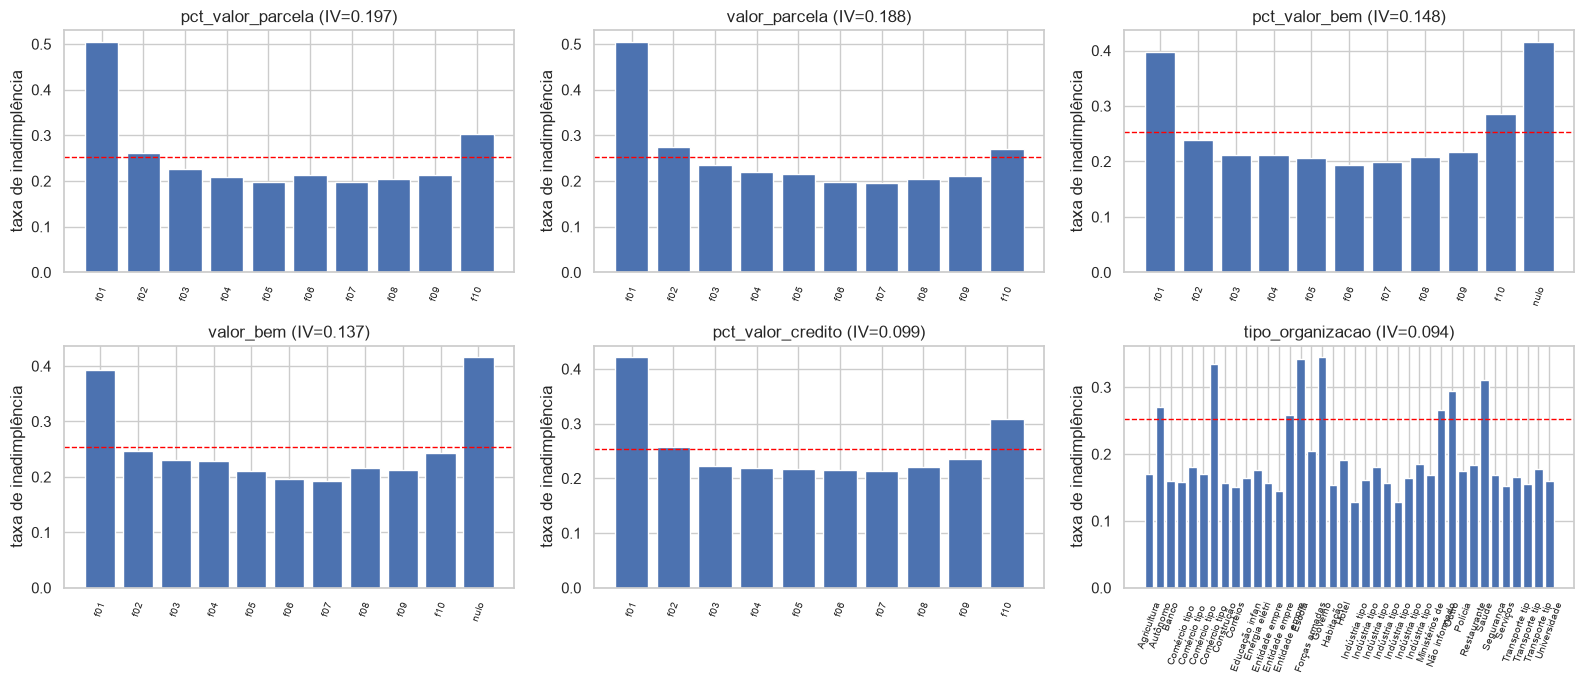

In [10]:
# WoE das variáveis com maior IV
top = biv.index[:6]
fig, ax = plt.subplots(2, 3, figsize=(16, 7))
for a_, c in zip(ax.ravel(), top):
    _, t = iv_woe(tr[c], y5); t = t[t.n >= 100]
    a_.bar(range(len(t)), t.taxa_inad.values); a_.set_xticks(range(len(t))); a_.set_xticklabels([str(i)[:14] for i in t.index], rotation=70, fontsize=7)
    a_.axhline(y5.mean(), color='red', ls='--', lw=1); a_.set_title(f'{c} (IV={biv.loc[c, "IV_dpd5"]:.3f})'); a_.set_ylabel('taxa de inadimplência')
plt.tight_layout(); plt.savefig(FIG / 'nb02_taxa_por_faixa_top.png', dpi=110); plt.show()

### Leitura
- **Target:** 98.861 contratos maduros; inadimplência de **22,5%** (DPD > 5) e **9,4%** (DPD > 30, contido no primeiro). Só 12,5% dos contratos têm atraso máximo entre 1 e 5 dias, e 67,7% nunca atrasaram.
- **Deriva do target:** a taxa é 25,3% no treino (2017–2022) e cai para 17,6% (2023) e 17,5% (2024+). Validação e teste são parecidos entre si; as probabilidades do treino ficarão infladas e precisam de **calibração** na validação antes da política.
- **Balanceamento:** DPD > 5 ≥ 20% no total (25% no treino): sem `scale_pos_weight`. DPD > 30 fica entre 5% e 20%: comparar pesos no nb03.
- **Sinal:** os três valores do contrato são as variáveis mais fortes (IV 0,08 a 0,19). O **percentil mantém o sinal** (`pct_valor_parcela` IV 0,197 contra 0,188 do valor bruto) e tem PSI ≈ 0 contra a submissão, enquanto os valores brutos têm PSI de 1,3 a 2,9. O modelo A (sem valores) perde as variáveis mais fortes.
- **Seleção sugerida pelos critérios do plano (nada removido ainda):** IV < 0,02 em `renda_anual`, `tipo_moradia`, `nivel_educacao`, `estado_civil`, `sexo`, `dia_semana_solicitacao`, `possui_imovel`, `hora`, `tipo_contrato` e `possui_carro`; PSI > 0,25 só nos valores brutos (modelo C, que é referência); nenhum VIF > 10 (máx. 8,5 em `pct_valor_credito`).
- **Colinearidade:** `valor_bem` × `valor_credito` (ρ = 0,99; o mesmo nos percentis), `qtd_filhos` × `qtd_membros_familia` (0,82). Para árvores é inofensivo; relevante para o baseline logístico.
- **Conflito com decisão anterior:** `sexo` e `idade` foram mantidos por decisão do usuário, mesmo que `sexo` tenha IV de 0,004.
